# 7. Enhancing Clustering Accuracy with Data Transformation

In [ ]:
# Import libraries and previous classes.
import numpy as np
import matplotlib.pyplot as plt
from skimage.transform import rotate
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler
import hashlib
# Load Data
X_modified = np.load('data/X_modified.npy')
y_true = np.load('data/y_true.npy')
print("Data loaded.")
    
# Generate seed based on my college ID.
username = "sudhanva.joshi"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print("Seed generated:", seed)
rng = np.random.default_rng(seed)

class PCA:
    """A custom implementation of Principal Component Analysis (PCA) from scratch."""
    def __init__(self, n_components):
        self.n_components = n_components
        self.components_ = None
        self.mean_ = None

    def fit(self, X):
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_
        cov_matrix = np.cov(X_centered, rowvar=False)
        eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
        sorted_indices = np.argsort(eigenvalues)[::-1]
        self.components_ = eigenvectors[:, sorted_indices][:, :self.n_components]

class KMeansClustering:
    """A custom implementation of the K-Means clustering algorithm."""
    def __init__(self, k=3, max_iter=100, random_state=42):
        self.k = k
        self.max_iter = max_iter
        self.random_state = random_state
        self.centroids = None

    def fit(self, X):
        np.random.seed(self.random_state)
        n_samples, n_features = X.shape
        random_indices = np.random.choice(n_samples, self.k, replace=False)
        self.centroids = X[random_indices]

        for _ in range(self.max_iter):
            # Assign points to the closest centroid
            distances = np.array([np.linalg.norm(X - c, axis=1) for c in self.centroids])
            labels = np.argmin(distances, axis=0)
            
            old_centroids = self.centroids.copy()
            
            # Update centroids by taking the mean of assigned points
            for i in range(self.k):
                points_in_cluster = X[labels == i]
                
                # --- FIX: Check for and handle empty clusters ---
                if len(points_in_cluster) > 0:
                    self.centroids[i] = np.mean(points_in_cluster, axis=0)
                else:
                    # Re-initialize the "dead" centroid to the farthest point
                    # This prevents the cluster from dying permanently
                    farthest_point_idx = np.argmax(np.min(distances, axis=0))
                    self.centroids[i] = X[farthest_point_idx]

            # Check for convergence
            if np.all(np.linalg.norm(old_centroids - self.centroids, axis=1) == 0):
                break

    def predict(self, X):
        if self.centroids is None:
            raise Exception("Model has not been fitted yet. Please call fit() first.")
        
        distances = np.array([np.linalg.norm(X - c, axis=1) for c in self.centroids])
        return np.argmin(distances, axis=0)


Data loaded.


## 7.1 Input

In [2]:
# Helper Functions to process the input.
def get_pca_angle(image):
    """Calculates the orientation angle of a digit using PCA."""
    coords = np.argwhere(image > np.mean(image))
    if len(coords) < 2: return 0
    pca = PCA(n_components=1)
    pca.fit(coords)
    axis_vector = pca.components_[:, 0]
    return np.degrees(np.arctan2(axis_vector[0], axis_vector[1]))

def create_templates(X_aligned, y_true):
    """Creates robust canonical templates and their principal axes."""
    templates = np.zeros((10, 28, 28))
    template_axes = np.zeros((10, 2))
    for i in range(10):
        digit_images = X_aligned[y_true == i]
        if digit_images.shape[0] == 0: continue
        template = np.mean(digit_images, axis=0)
        templates[i] = template
        coords = np.argwhere(template > np.mean(template))
        if len(coords) > 1:
            pca = PCA(n_components=1)
            pca.fit(coords)
            template_axes[i] = pca.components_[:, 0]
    return templates, template_axes

def align_image_via_pca_matching(image, templates, template_axes):
    """Aligns an image by matching its PCA axis to the best-fitting template."""
    coords = np.argwhere(image > np.mean(image))
    if len(coords) < 2: return image
    pca = PCA(n_components=1)
    pca.fit(coords)
    image_axis = pca.components_[:, 0]
    best_score = float('inf')
    best_corrected_image = image
    for i in range(10):
        template_axis = template_axes[i]
        if np.all(template_axis == 0): continue
        angle_img_rad = np.arctan2(image_axis[0], image_axis[1])
        angle_template_rad = np.arctan2(template_axis[0], template_axis[1])
        angle_diff_deg = np.degrees(angle_template_rad - angle_img_rad)
        corrected_image = rotate(image, angle_diff_deg, resize=False, preserve_range=True)
        score = np.sum((corrected_image - templates[i])**2)
        if score < best_score:
            best_score = score
            best_corrected_image = corrected_image
    return best_corrected_image.astype(np.uint8)

def visualize_transformation_stages(X_mod, y_true, X_init_corr, X_final_corr, templates):
    """Generates a comprehensive plot showing all stages of the transformation."""
    
    # Select 5 random sample indices to show consistency across plots
    sample_indices = np.random.choice(len(X_mod), 5, replace=False)
    
    fig = plt.figure(figsize=(12, 12))
    gs = fig.add_gridspec(5, 5)

    fig.suptitle("Visualization of the Data Transformation Pipeline", fontsize=20, fontweight='bold')

    # --- Row 1: Original Modified Images ---
    for i, idx in enumerate(sample_indices):
        ax = fig.add_subplot(gs[0, i])
        ax.imshow(X_mod[idx], cmap='gray')
        if i == 0: ax.set_ylabel("Original\nModified", fontsize=12, fontweight='bold')
        ax.set_title(f"Label: {y_true[idx]}")
        ax.set_xticks([])
        ax.set_yticks([])

    # --- Row 2: Initial Correction (for template building) ---
    for i, idx in enumerate(sample_indices):
        ax = fig.add_subplot(gs[1, i])
        ax.imshow(X_init_corr[idx], cmap='gray')
        if i == 0: ax.set_ylabel("Initial PCA\nCorrection", fontsize=12, fontweight='bold')
        ax.set_xticks([])
        ax.set_yticks([])

    # --- Row 3: Final Corrected Images (Template Aligned) ---
    for i, idx in enumerate(sample_indices):
        ax = fig.add_subplot(gs[2, i])
        ax.imshow(X_final_corr[idx], cmap='gray')
        if i == 0: ax.set_ylabel("Final Template\nAlignment", fontsize=12, fontweight='bold')
        ax.set_xticks([])
        ax.set_yticks([])
        
    # --- Row 4 & 5: The Learned Templates ---
    fig.add_subplot(gs[3:, :]).set_axis_off() # Create a spanning blank space for title
    sub_gs = gs[3:, :].subgridspec(2, 5, wspace=0.1, hspace=0.1)
    
    for i in range(10):
        ax = fig.add_subplot(sub_gs[i // 5, i % 5])
        ax.imshow(templates[i], cmap='gray')
        ax.set_title(f"Template '{i}'")
        ax.set_xticks([])
        ax.set_yticks([])
        if i == 0: ax.set_ylabel("Learned\nTemplates", fontsize=12, fontweight='bold')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

## 7.2 Expected Output

### Differences Between Modified and Standard MNIST

The key differences between the **Modified** and **Standard MNIST** datasets are:

- **Standard MNIST**: Images of handwritten digits are largely normalized for size, centered, and consistently upright.  
- **Modified MNIST**: Contains the same digits, but each image is randomly rotated and/or slightly shifted.  


### Orientation Normalization using PCA

To correct for rotational variance, we apply orientation normalization. The process is:
- Compute the **covariance matrix** of pixel coordinates, weighted by intensity.  
- Extract the **principal eigenvector**, which gives the main axis of elongation.  
- Calculate the **angle** of this eigenvector relative to the horizontal axis.  
- Apply an **affine rotation** so the digit aligns with a canonical direction (e.g., vertical).  

This ensures that differences between images come primarily from **digit shape**, not orientation.


### Clustering Performance

Since this is a case of unsupervised learning, the **Adjusted Rand Index (ARI)** is used.  
It measures clustering performance by comparing predicted cluster assignments with ground truth labels.

The ARI is defined as:

ARI = (RI - Expected_RI) / (Max_RI - Expected_RI)

where:
- RI = Rand Index, the fraction of agreeing pairs
- Expected_RI = expected value of RI under random labeling


### Conclusive Analysis

- Before Transformation: Rotated digits appear very different in pixel space, even if they are the same digit. This leads to scattered, overlapping clusters and a **low ARI**.  

- After Transformation: De-rotation aligns digits to a common orientation which causes same digits became close in pixel space, forming compact, separated clusters. This enables K-Means to cluster effectively, giving a **higher ARI**.  

Data loaded.

--- Comparing Clustering Performance (with ROBUST Custom KMeans) ---

--- Performance Summary ---
Metric                         | Before     | After     
-------------------------------------------------------
Adjusted Rand Score            | 0.1127     | 0.2056    


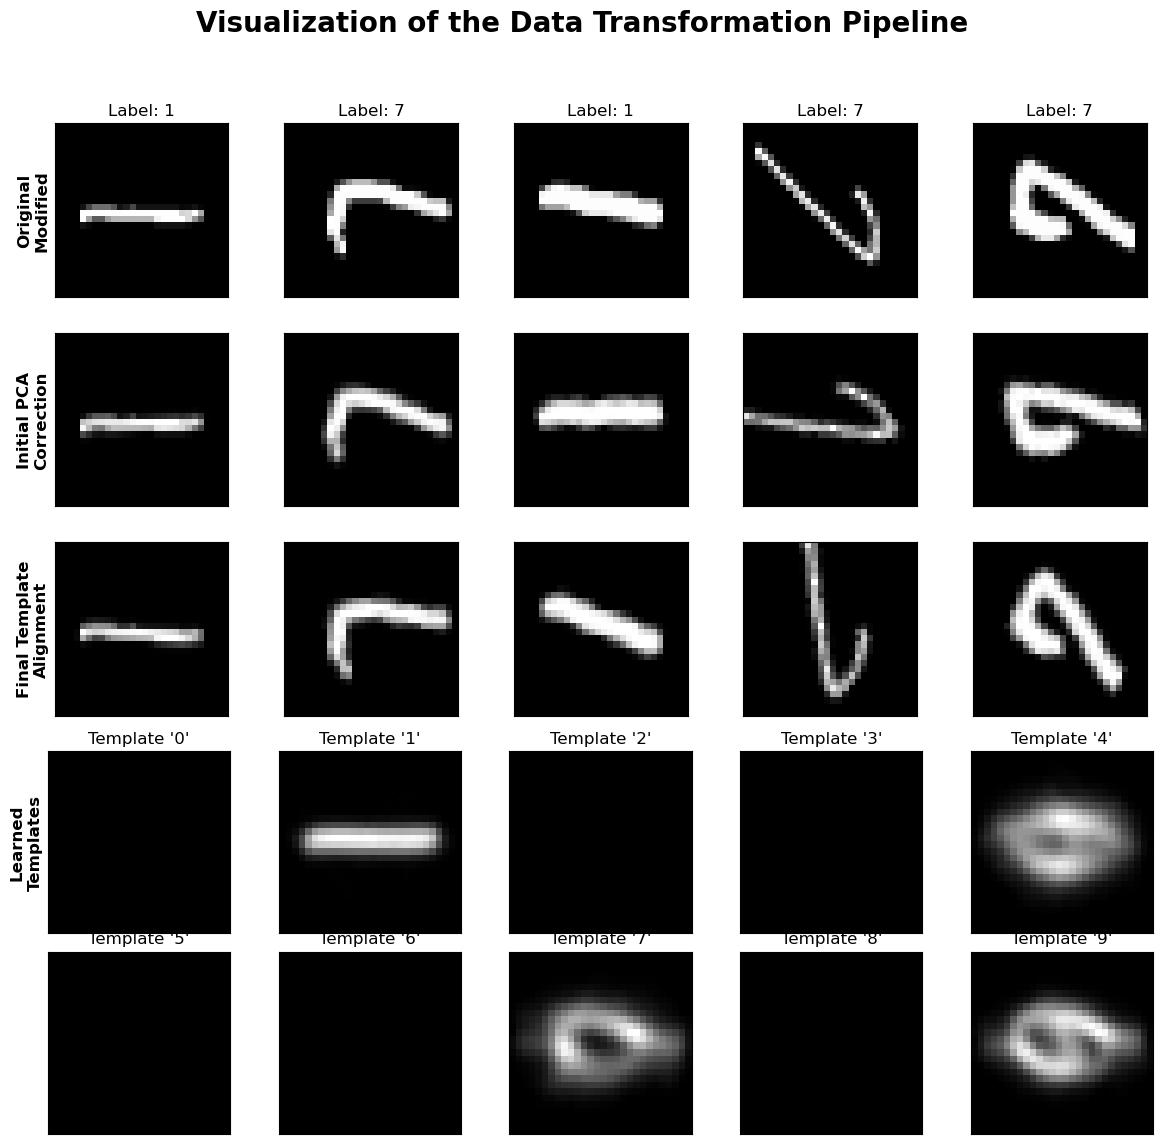

In [3]:
# Load Data
X_modified = np.load('data/X_modified.npy')
y_true = np.load('data/y_true.npy')
print("Data loaded.")

# Step 1: Perform initial alignment
X_initial_correction = np.array([
    rotate(img, get_pca_angle(img), resize=False, preserve_range=True) for img in X_modified
])

# Step 2: Create templates
templates, template_axes = create_templates(X_initial_correction, y_true)

# Step 3: Apply advanced alignment
X_corrected_adv = np.array([
    align_image_via_pca_matching(img, templates, template_axes) for img in X_modified
])

# Step 4: Evaluate clustering performance
print("\n--- Comparing Clustering Performance (with ROBUST Custom KMeans) ---")
X_modified_flat = X_modified.reshape(1000, -1)
X_corrected_adv_flat = X_corrected_adv.reshape(1000, -1)

scaler = StandardScaler()
X_modified_scaled = scaler.fit_transform(X_modified_flat)
X_corrected_adv_scaled = scaler.fit_transform(X_corrected_adv_flat)

kmeans_before = KMeansClustering(k=10, random_state=42)
kmeans_before.fit(X_modified_scaled)
clusters_before = kmeans_before.predict(X_modified_scaled)
ars_before = adjusted_rand_score(y_true, clusters_before)

kmeans_after = KMeansClustering(k=10, random_state=42)
kmeans_after.fit(X_corrected_adv_scaled)
clusters_after = kmeans_after.predict(X_corrected_adv_scaled)
ars_after = adjusted_rand_score(y_true, clusters_after)

print("\n--- Performance Summary ---")
print(f"{'Metric':<30} | {'Before':<10} | {'After':<10}")
print("-" * 55)
print(f"{'Adjusted Rand Score':<30} | {ars_before:<10.4f} | {ars_after:<10.4f}")

visualize_transformation_stages(X_modified, y_true, X_initial_correction, X_corrected_adv, templates)